In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))

df = pd.read_csv("Online_Retail_Business_Analysis_Cleaned.csv")

df.head()

Saving Online_Retail_Business_Analysis_Cleaned.csv to Online_Retail_Business_Analysis_Cleaned.csv


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/01/2010 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,12/01/2010 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/01/2010 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/01/2010 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/01/2010 08:26:00,3.39,17850.0,United Kingdom,20.34


In [4]:
df.shape

(536641, 9)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 536641 entries, 0 to 536640
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    536641 non-null  object 
 1   StockCode    536641 non-null  object 
 2   Description  535187 non-null  object 
 3   Quantity     536641 non-null  int64  
 4   InvoiceDate  536641 non-null  object 
 5   UnitPrice    536641 non-null  float64
 6   CustomerID   401604 non-null  float64
 7   Country      536641 non-null  object 
 8   Revenue      536641 non-null  float64
dtypes: float64(3), int64(1), object(5)
memory usage: 36.8+ MB


In [6]:
df.describe()

,Quantity,UnitPrice,CustomerID,Revenue
count,536641.000000,536641.000000,401604.000000,536641.000000
mean,9.620029,4.632656,15281.160818,18.123861
std,219.130156,97.233118,1714.006089,380.656263
min,-80995.000000,-11062.060000,12346.000000,-168469.600000
25%,1.000000,1.250000,13939.000000,3.750000
50%,3.000000,2.080000,15145.000000,9.870000
75%,10.000000,4.130000,16784.000000,17.400000
max,80995.000000,38970.000000,18287.000000,168469.600000


In [7]:
df["Revenue"].sum()

np.float64(9726006.953999998)

In [8]:
df["Revenue"].mean()

np.float64(18.123861117581395)

In [9]:
df["Revenue"].min()

-168469.6

In [10]:
df["Revenue"].max()

168469.6

In [11]:
df["Revenue"].count()

np.int64(536641)

In [12]:
df.groupby("Country")["Revenue"].sum().sort_values(ascending=False)

,Revenue
Country,
United Kingdom,8167128.184
Netherlands,284661.540
Eire,262993.380
Germany,221509.470
France,197317.110
Australia,137009.770
Switzerland,56363.050
Spain,54756.030
Belgium,40910.960


In [13]:
df.groupby("Country")["Revenue"].agg(
    ["sum", "mean", "min", "max", "count"]
)

,sum,mean,min,max,count
Country,,,,,
Australia,137009.770,108.910787,-425.00,1718.40,1258
Austria,10154.320,25.322494,-21.25,360.00,401
Bahrain,548.400,28.863158,-205.74,205.74,19
Belgium,40910.960,19.773301,-19.95,165.00,2069
Brazil,1143.600,35.737500,15.00,175.20,32
Canada,3666.380,24.280662,2.50,550.94,151
Channel Islands,20076.390,26.520991,-293.00,408.00,757
Cyprus,12858.760,21.045434,-320.69,320.69,611
Czech Republic,707.720,23.590667,-35.76,70.80,30


In [14]:
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

df["Average_Item_Value"] = df["Revenue"] / df["Quantity"].replace(0, np.nan)

df["Revenue_Category"] = np.where(
    df["Revenue"] >= df["Revenue"].mean(),
    "High Revenue",
    "Low Revenue"
)

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Average_Item_Value,Revenue_Category
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/01/2010 08:26:00,2.55,17850.0,United Kingdom,15.30,2.55,Low Revenue
1,536365,71053,WHITE METAL LANTERN,6,12/01/2010 08:26:00,3.39,17850.0,United Kingdom,20.34,3.39,High Revenue
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/01/2010 08:26:00,2.75,17850.0,United Kingdom,22.00,2.75,High Revenue
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/01/2010 08:26:00,3.39,17850.0,United Kingdom,20.34,3.39,High Revenue
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/01/2010 08:26:00,3.39,17850.0,United Kingdom,20.34,3.39,High Revenue


In [15]:
df[[
    "InvoiceNo",
    "Description",
    "Quantity",
    "UnitPrice",
    "Revenue",
    "Average_Item_Value",
    "Revenue_Category"
]]

,InvoiceNo,Description,Quantity,UnitPrice,Revenue,Average_Item_Value,Revenue_Category
0,536365,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55,15.30,2.55,Low Revenue
1,536365,WHITE METAL LANTERN,6,3.39,20.34,3.39,High Revenue
2,536365,CREAM CUPID HEARTS COAT HANGER,8,2.75,22.00,2.75,High Revenue
3,536365,KNITTED UNION FLAG HOT WATER BOTTLE,6,3.39,20.34,3.39,High Revenue
4,536365,RED WOOLLY HOTTIE WHITE HEART.,6,3.39,20.34,3.39,High Revenue
...,...,...,...,...,...,...,...
536636,581587,PACK OF 20 SPACEBOY NAPKINS,12,0.85,10.20,0.85,Low Revenue
536637,581587,CHILDREN'S APRON DOLLY GIRL,6,2.10,12.60,2.10,Low Revenue
536638,581587,CHILDRENS CUTLERY DOLLY GIRL,4,4.15,16.60,4.15,Low Revenue
536639,581587,CHILDRENS CUTLERY CIRCUS PARADE,4,4.15,16.60,4.15,Low Revenue


In [16]:
df.sort_values(
    "Revenue",
    ascending=False
)[["InvoiceNo", "Country", "Description", "Revenue"]].head(5)

,InvoiceNo,Country,Description,Revenue
535160,581483,United Kingdom,"PAPER CRAFT , LITTLE BIRDIE",168469.60
61006,541431,United Kingdom,MEDIUM CERAMIC TOP STORAGE JAR,77183.60
220825,556444,United Kingdom,PICNIC BASKET WICKER 60 PIECES,38970.00
14757,537632,United Kingdom,AMAZON FEE,13541.33
297645,A563185,United Kingdom,Adjust bad debt,11062.06


In [17]:
df[df["Revenue"] > df["Revenue"].mean()][
    ["InvoiceNo", "Country", "Description", "Revenue"]
]

,InvoiceNo,Country,Description,Revenue
1,536365,United Kingdom,WHITE METAL LANTERN,20.34
2,536365,United Kingdom,CREAM CUPID HEARTS COAT HANGER,22.00
3,536365,United Kingdom,KNITTED UNION FLAG HOT WATER BOTTLE,20.34
4,536365,United Kingdom,RED WOOLLY HOTTIE WHITE HEART.,20.34
6,536365,United Kingdom,GLASS STAR FROSTED T-LIGHT HOLDER,25.50
...,...,...,...,...
536625,581586,United Kingdom,DOORMAT RED RETROSPOT,70.80
536626,581587,France,CIRCUS PARADE LUNCH BOX,23.40
536627,581587,France,PLASTERS IN TIN CIRCUS PARADE,19.80
536628,581587,France,PLASTERS IN TIN STRONGMAN,19.80


In [18]:
df.loc[
    df["Revenue"].idxmax(),
    ["InvoiceNo", "Description", "Quantity", "Revenue"]
]

,535160
InvoiceNo,581483
Description,"PAPER CRAFT , LITTLE BIRDIE"
Quantity,80995
Revenue,168469.6


In [19]:
df.groupby("Description")["Revenue"].sum().sort_values(
    ascending=False
).head(10)

,Revenue
Description,
DOTCOM POSTAGE,206245.48
REGENCY CAKESTAND 3 TIER,164459.49
WHITE HANGING HEART T-LIGHT HOLDER,99612.42
PARTY BUNTING,98243.88
JUMBO BAG RED RETROSPOT,92175.79
RABBIT NIGHT LIGHT,66661.63
POSTAGE,66230.64
PAPER CHAIN KIT 50'S CHRISTMAS,63715.24
ASSORTED COLOUR BIRD ORNAMENT,58792.42


In [20]:
df.groupby("Country")["Revenue"].sum().sort_values(
    ascending=False
)

,Revenue
Country,
United Kingdom,8167128.184
Netherlands,284661.540
Eire,262993.380
Germany,221509.470
France,197317.110
Australia,137009.770
Switzerland,56363.050
Spain,54756.030
Belgium,40910.960


In [21]:
df[df["Quantity"] > 10][
    ["InvoiceNo", "Description", "Quantity", "Revenue"]
]

,InvoiceNo,Description,Quantity,Revenue
9,536367,ASSORTED COLOUR BIRD ORNAMENT,32,54.08
26,536370,ALARM CLOCK BAKELIKE PINK,24,90.00
27,536370,ALARM CLOCK BAKELIKE RED,24,90.00
28,536370,ALARM CLOCK BAKELIKE GREEN,12,45.00
29,536370,PANDA AND BUNNIES STICKER SHEET,12,10.20
...,...,...,...,...
536626,581587,CIRCUS PARADE LUNCH BOX,12,23.40
536627,581587,PLASTERS IN TIN CIRCUS PARADE,12,19.80
536628,581587,PLASTERS IN TIN STRONGMAN,12,19.80
536634,581587,SPACEBOY LUNCH BOX,12,23.40


In [22]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")

df.dtypes

,0
InvoiceNo,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[ns]
UnitPrice,float64
CustomerID,float64
Country,object
Revenue,float64
Average_Item_Value,float64


In [23]:
df["Year"] = df["InvoiceDate"].dt.year

df["Month"] = df["InvoiceDate"].dt.month

df["Month_Name"] = df["InvoiceDate"].dt.month_name()

df["Day"] = df["InvoiceDate"].dt.day

df["Day_Name"] = df["InvoiceDate"].dt.day_name()

df[[
    "InvoiceNo",
    "InvoiceDate",
    "Year",
    "Month",
    "Month_Name",
    "Day",
    "Day_Name"
]]

,InvoiceNo,InvoiceDate,Year,Month,Month_Name,Day,Day_Name
0,536365,2010-12-01 08:26:00,2010,12,December,1,Wednesday
1,536365,2010-12-01 08:26:00,2010,12,December,1,Wednesday
2,536365,2010-12-01 08:26:00,2010,12,December,1,Wednesday
3,536365,2010-12-01 08:26:00,2010,12,December,1,Wednesday
4,536365,2010-12-01 08:26:00,2010,12,December,1,Wednesday
...,...,...,...,...,...,...,...
536636,581587,2011-12-09 12:50:00,2011,12,December,9,Friday
536637,581587,2011-12-09 12:50:00,2011,12,December,9,Friday
536638,581587,2011-12-09 12:50:00,2011,12,December,9,Friday
536639,581587,2011-12-09 12:50:00,2011,12,December,9,Friday


In [24]:
df.groupby("Year")["Revenue"].sum()

,Revenue
Year,
2010,746723.610
2011,8979283.344


In [25]:
df.groupby(["Year", "Month"])["Revenue"].sum()

Year  Month
2010  12        746723.610
2011  1         558448.560
      2         497026.410
      3         682013.980
      4         492367.841
      5         722094.100
      6         689977.230
      7         680156.991
      8         681386.460
      9        1017596.682
      10       1069368.230
      11       1456145.800
      12        432701.060
Name: Revenue, dtype: float64

In [26]:
df.groupby("Month_Name")["Revenue"].sum()

,Revenue
Month_Name,
April,492367.841
August,681386.460
December,1179424.670
February,497026.410
January,558448.560
July,680156.991
June,689977.230
March,682013.980
May,722094.100


In [27]:
df.groupby("Day_Name")["Revenue"].sum()

,Revenue
Day_Name,
Friday,1537958.621
Monday,1584895.301
Sunday,798659.461
Thursday,2108701.530
Tuesday,1965703.611
Wednesday,1730088.430


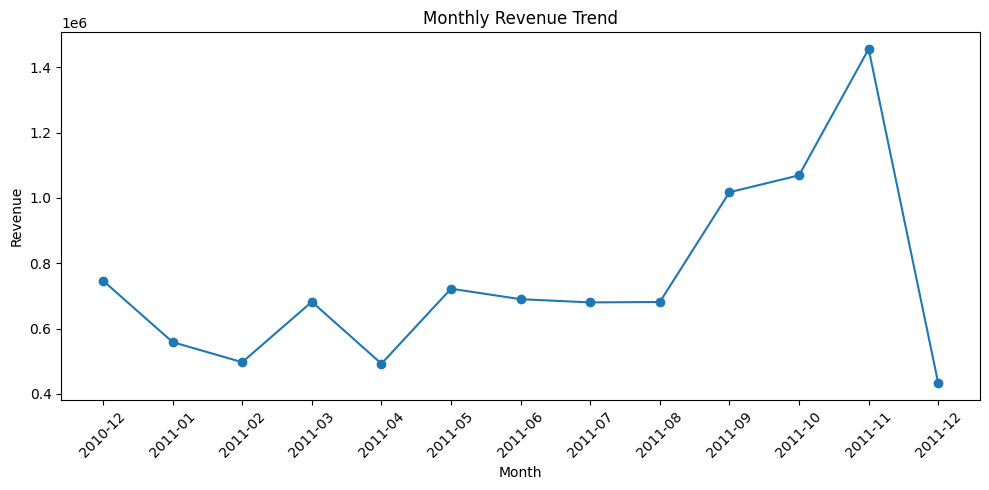

In [28]:
monthly_revenue = df.groupby(
    df["InvoiceDate"].dt.to_period("M")
)["Revenue"].sum()

plt.figure(figsize=(10, 5))
plt.plot(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    marker="o"
)

plt.xlabel("Month")
plt.ylabel("Revenue")
plt.title("Monthly Revenue Trend")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

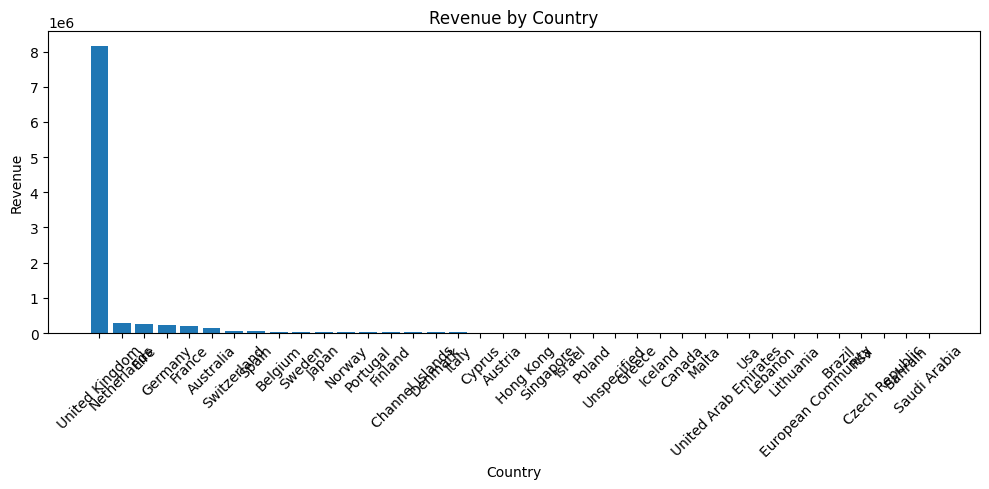

In [29]:
country_revenue = df.groupby("Country")["Revenue"].sum().sort_values(
    ascending=False
)

plt.figure(figsize=(10, 5))
plt.bar(country_revenue.index, country_revenue.values)

plt.xlabel("Country")
plt.ylabel("Revenue")
plt.title("Revenue by Country")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

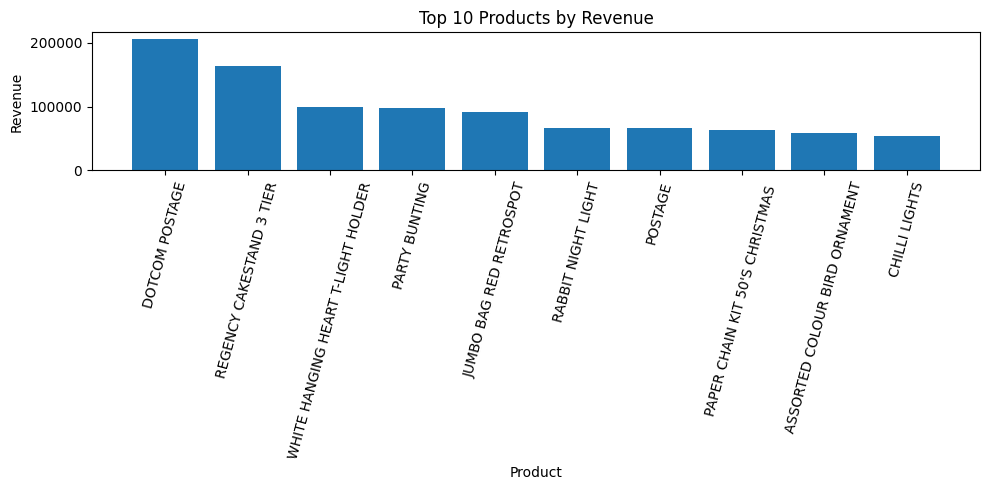

In [30]:
product_revenue = df.groupby("Description")["Revenue"].sum().sort_values(
    ascending=False
).head(10)

plt.figure(figsize=(10, 5))
plt.bar(product_revenue.index, product_revenue.values)

plt.xlabel("Product")
plt.ylabel("Revenue")
plt.title("Top 10 Products by Revenue")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

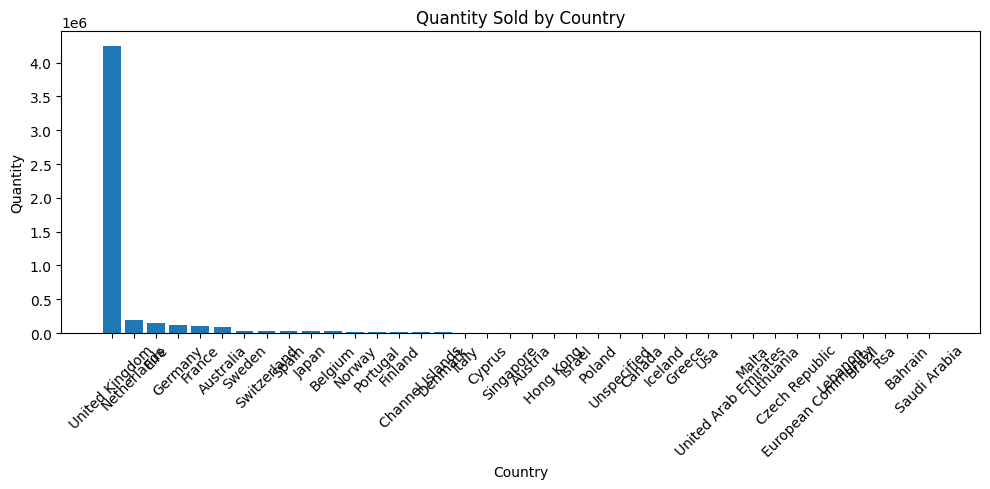

In [31]:
country_quantity = df.groupby("Country")["Quantity"].sum().sort_values(
    ascending=False
)

plt.figure(figsize=(10, 5))
plt.bar(country_quantity.index, country_quantity.values)

plt.xlabel("Country")
plt.ylabel("Quantity")
plt.title("Quantity Sold by Country")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

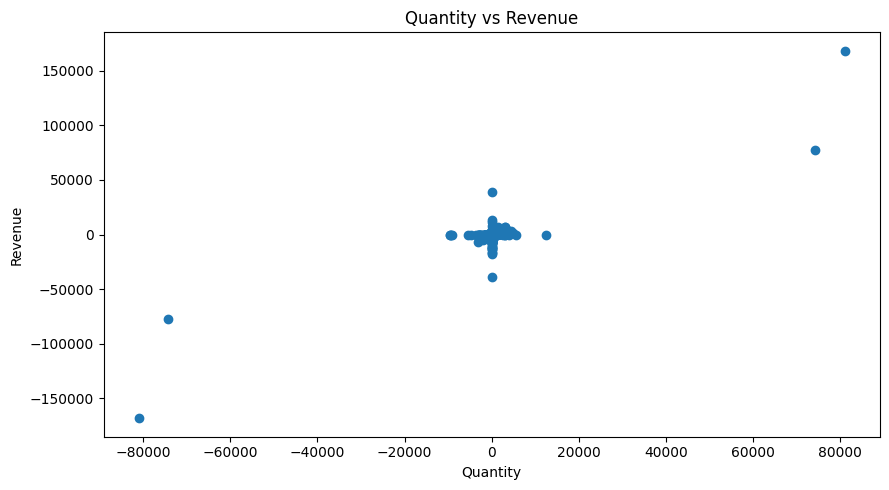

In [32]:
plt.figure(figsize=(9, 5))
plt.scatter(df["Quantity"], df["Revenue"])

plt.xlabel("Quantity")
plt.ylabel("Revenue")
plt.title("Quantity vs Revenue")
plt.tight_layout()
plt.show()

In [33]:
total_revenue = df["Revenue"].sum()

average_revenue = df["Revenue"].mean()

highest_revenue = df["Revenue"].max()

lowest_revenue = df["Revenue"].min()

top_country = df.groupby("Country")["Revenue"].sum().idxmax()

top_country_revenue = df.groupby("Country")["Revenue"].sum().max()

top_product = df.groupby("Description")["Revenue"].sum().idxmax()

top_product_revenue = df.groupby("Description")["Revenue"].sum().max()

highest_month = df.groupby(
    df["InvoiceDate"].dt.to_period("M")
)["Revenue"].sum().idxmax()

highest_month_revenue = df.groupby(
    df["InvoiceDate"].dt.to_period("M")
)["Revenue"].sum().max()

print("Total Revenue:", total_revenue)
print("Average Revenue:", average_revenue)
print("Highest Revenue:", highest_revenue)
print("Lowest Revenue:", lowest_revenue)
print("Top Country:", top_country, "-", top_country_revenue)
print("Top Product:", top_product, "-", top_product_revenue)
print("Highest Revenue Month:", highest_month, "-", highest_month_revenue)

Total Revenue: 9726006.953999998
Average Revenue: 18.123861117581395
Highest Revenue: 168469.6
Lowest Revenue: -168469.6
Top Country: United Kingdom - 8167128.184
Top Product: DOTCOM POSTAGE - 206245.48
Highest Revenue Month: 2011-11 - 1456145.8


In [34]:
insights = [
    f"{top_country} has the highest total revenue.",
    f"{top_product} is the highest revenue-generating product.",
    f"{highest_month} has the highest monthly revenue.",
    f"The total revenue is {total_revenue:.2f}.",
    f"The average revenue per record is {average_revenue:.2f}.",
    f"The highest revenue record is {highest_revenue:.2f}.",
    f"The lowest revenue record is {lowest_revenue:.2f}."
]

for i, insight in enumerate(insights, 1):
    print(f"{i}. {insight}")

1. United Kingdom has the highest total revenue.
2. DOTCOM POSTAGE is the highest revenue-generating product.
3. 2011-11 has the highest monthly revenue.
4. The total revenue is 9726006.95.
5. The average revenue per record is 18.12.
6. The highest revenue record is 168469.60.
7. The lowest revenue record is -168469.60.


In [35]:
df.to_csv("Online_Retail_Final_Analysis.csv", index=False)

print("Final analysed dataset saved successfully!")

Final analysed dataset saved successfully!
